# 07 · Estadística inferencial, costo del error y comparación contra reglas simples

> **Flujo del proyecto** (diagrama del profesor)
> `01 Limpieza` → `02 Exploración` → `03 Creación de variables` → `04 Preparación (split temporal + folds)` →
> `05a Logística` · `05b Random Forest` · `05c XGBoost` · `05d Red neuronal` → `06 Selección y prueba final` →
> **`07 Estadística y costo del error`** (complemento para el reporte)

**Qué agrega este notebook** (lo pide la rúbrica del proyecto):

1. **Estadística descriptiva** de las variables clave, separada por clase (sólo con el periodo de entrenamiento).
2. **Intervalos de confianza y pruebas de hipótesis** que respaldan los hallazgos principales.
3. **Cuánto cuesta equivocarse**: reseñas negativas adicionales, recompra, valor de los pedidos y punto de equilibrio de una alerta.
4. **Comparación contra la solución más simple**: reglas de una sola variable frente a los modelos en el periodo de prueba.

**Entrada:** `datos/interim/`, `datos/processed/dataset_pedidos.parquet`, `reportes/metricas/resultados.json` ·
**Salida:** `reportes/metricas/complementos.json` y `reportes/figuras/baselines_test.png`.

**Regla anti-fuga:** este notebook **no cambia ninguna decisión del modelo**. Lo que mira el periodo de prueba (sección 4) sólo
evalúa reglas fijas; la dirección de cada regla se decide con el periodo de entrenamiento.

In [1]:
import sys, json, warnings
from pathlib import Path

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import average_precision_score, roc_auc_score
from IPython.display import display

from src import config, viz
viz.aplicar_estilo()
pd.set_option("display.width", 200)
Z = 1.959964  # cuantil normal para 95 %

In [2]:
orders = pd.read_parquet(config.DATOS_INTERIM / "orders.parquet")
reviews = pd.read_parquet(config.DATOS_INTERIM / "reviews.parquet")
customers = pd.read_parquet(config.DATOS_INTERIM / "customers.parquet")
df = pd.read_parquet(config.DATOS_PROCESSED / "dataset_pedidos.parquet")
meta_test = pd.read_parquet(config.DATOS_PROCESSED / "meta_test.parquet")
res = json.loads((config.METRICAS / "resultados.json").read_text())

corte = pd.Timestamp(config.FECHA_CORTE_TEST)
estudio = orders[orders["order_purchase_timestamp"] >= config.FECHA_INICIO_MODELO].copy()
train = df[(df["order_purchase_timestamp"] >= config.FECHA_INICIO_MODELO) & (df["order_purchase_timestamp"] < corte)]
test = df[df["order_id"].isin(meta_test["order_id"])]
print(f"Periodo de estudio: {len(estudio):,} pedidos | train (sin purga): {len(train):,} | test: {len(test):,}")
comp = {}

Periodo de estudio: 96,201 pedidos | train (sin purga): 70,851 | test: 25,350


## 1. Estadística descriptiva de las variables clave (entrenamiento)

Para cada variable comparamos la **mediana** y la **media** de los pedidos a tiempo y tardíos. Como medida de tamaño del efecto
usamos el **AUC univariado**: la probabilidad de que un pedido tardío elegido al azar tenga un valor mayor que uno puntual
(0.5 = la variable no separa; más lejos de 0.5 = separa mejor). Equivale al estadístico U de Mann-Whitney normalizado.

In [3]:
CLAVE = {
    "estimated_delivery_days": "Días de entrega prometidos",
    "min_dias_limite_envio": "Plazo mínimo del vendedor para despachar (días)",
    "avg_distance_km": "Distancia vendedor–cliente (km)",
    "total_price": "Precio total (R$)",
    "total_freight": "Flete total (R$)",
    "avg_product_weight": "Peso promedio del producto (g)",
    "seller_late_rate": "Historial de retrasos del vendedor",
    "ruta_late_rate": "Historial de retrasos de la ruta",
    "global_late_30d": "Tasa de retraso del sistema, 30 días",
    "estado_late_30d": "Tasa de retraso hacia el estado, 30 días",
    "pedidos_ult_7d": "Pedidos de los últimos 7 días",
}
filas = []
for col, nombre in CLAVE.items():
    s = train[[col, "delivery_late"]].dropna()
    a, t = s.loc[s["delivery_late"] == 0, col], s.loc[s["delivery_late"] == 1, col]
    filas.append({"variable": col, "Variable": nombre,
                  "Mediana a tiempo": a.median(), "Mediana tardío": t.median(),
                  "Media a tiempo": a.mean(), "Media tardío": t.mean(),
                  "AUC univariado": roc_auc_score(s["delivery_late"], s[col])})
descriptiva = pd.DataFrame(filas)
display(descriptiva.drop(columns="variable").round(3))
comp["descriptiva"] = descriptiva.to_dict(orient="records")
comp["n_train_descriptiva"] = int(len(train))

,Variable,Mediana a tiempo,Mediana tardío,Media a tiempo,Media tardío,AUC univariado
0,Días de entrega prometidos,23.627,23.460,24.496,24.126,0.493
1,Plazo mínimo del vendedor para despachar (días),6.015,6.014,6.882,6.738,0.494
2,Distancia vendedor–cliente (km),436.691,563.847,597.030,802.723,0.599
3,Precio total (R$),84.990,92.000,134.835,150.974,0.531
4,Flete total (R$),16.700,18.230,21.990,25.707,0.590
5,Peso promedio del producto (g),700.000,800.000,2142.899,2526.725,0.522
6,Historial de retrasos del vendedor,0.034,0.042,0.041,0.050,0.590
7,Historial de retrasos de la ruta,0.034,0.042,0.040,0.059,0.648
8,"Tasa de retraso del sistema, 30 días",0.044,0.050,0.068,0.069,0.567
9,"Tasa de retraso hacia el estado, 30 días",0.036,0.059,0.062,0.087,0.630


**Lectura:** en entrenamiento, las variables que más separan las clases por sí solas son la **carga de pedidos de los últimos
7 días**, el **historial de la ruta** y la **tasa de retraso reciente hacia el estado** (AUC 0.63–0.67). Los días prometidos casi
no separan por sí solos (AUC ≈ 0.49), porque la fecha prometida ya incorpora un margen; su efecto aparece al combinarlos con las
demás variables. Ninguna variable aislada pasa de 0.67: por eso hace falta un modelo multivariable.

## 2. Intervalos de confianza y pruebas de hipótesis

### 2.1 Tasa de retraso y cambio entre periodos
Intervalo de Wilson al 95 % para cada proporción y prueba χ² de independencia entre periodo (train / test) y retraso.
Si el retraso no dependiera del periodo, ambas tasas serían iguales (hipótesis nula).

In [4]:
def wilson(k, n, z=Z):
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return {"p": p, "li": c - h, "ls": c + h, "k": int(k), "n": int(n)}

es_tr = estudio["order_purchase_timestamp"] < corte
tasas = {
    "global": wilson(estudio["delivery_late"].sum(), len(estudio)),
    "train": wilson(estudio.loc[es_tr, "delivery_late"].sum(), es_tr.sum()),
    "test": wilson(estudio.loc[~es_tr, "delivery_late"].sum(), (~es_tr).sum()),
}
chi2, p_drift, _, _ = stats.chi2_contingency(pd.crosstab(es_tr, estudio["delivery_late"]))
for k, v in tasas.items():
    print(f"{k:>6}: {v['p']:.2%}  IC 95 % [{v['li']:.2%}, {v['ls']:.2%}]  (n = {v['n']:,})")
print(f"χ² = {chi2:.1f}, p = {p_drift:.1e}  →  la tasa de retraso cambió entre periodos (deriva).")
comp["tasas"] = tasas
comp["drift"] = {"chi2": chi2, "p": p_drift}

global: 6.79%  IC 95 % [6.63%, 6.95%]  (n = 96,201)
 train: 7.64%  IC 95 % [7.45%, 7.84%]  (n = 70,851)
  test: 4.40%  IC 95 % [4.15%, 4.66%]  (n = 25,350)
χ² = 310.3, p = 1.9e-69  →  la tasa de retraso cambió entre periodos (deriva).


### 2.2 ¿Un pedido tardío recibe peores reseñas?
Comparamos la calificación promedio (diferencia de medias con prueba t de Welch y prueba no paramétrica de Mann-Whitney) y la
proporción de reseñas de 1–2 estrellas (diferencia de proporciones con intervalo normal y prueba χ²). Las reseñas **nunca** se usan
como variable del modelo: sólo dimensionan el problema.

In [5]:
rev = reviews.groupby("order_id")["review_score"].mean().rename("score")
o_rev = estudio.join(rev, on="order_id").dropna(subset=["score"])
a = o_rev.loc[o_rev["delivery_late"] == 0, "score"]
t = o_rev.loc[o_rev["delivery_late"] == 1, "score"]

dif = t.mean() - a.mean()
se = np.sqrt(t.var(ddof=1) / len(t) + a.var(ddof=1) / len(a))
p_welch = stats.ttest_ind(t, a, equal_var=False).pvalue
p_mw = stats.mannwhitneyu(t, a).pvalue

pa, pt = (a <= 2).mean(), (t <= 2).mean()
se_p = np.sqrt(pa * (1 - pa) / len(a) + pt * (1 - pt) / len(t))
chi2_r, p_chi_r, _, _ = stats.chi2_contingency(pd.crosstab(o_rev["delivery_late"], o_rev["score"] <= 2))

print(f"Calificación: a tiempo {a.mean():.2f} vs tardío {t.mean():.2f} | diferencia {dif:.2f} "
      f"IC 95 % [{dif - Z * se:.2f}, {dif + Z * se:.2f}] | Welch p = {p_welch:.1e} | Mann-Whitney p = {p_mw:.1e}")
print(f"1–2 estrellas: a tiempo {pa:.1%} vs tardío {pt:.1%} | diferencia {pt - pa:.1%} "
      f"IC 95 % [{pt - pa - Z * se_p:.1%}, {pt - pa + Z * se_p:.1%}] | χ² p = {p_chi_r:.1e}")
comp["reviews"] = {"n_a_tiempo": int(len(a)), "n_tardio": int(len(t)), "media_a": a.mean(), "media_t": t.mean(),
                   "dif": dif, "dif_li": dif - Z * se, "dif_ls": dif + Z * se, "p_welch": p_welch, "p_mw": p_mw,
                   "p12_a": pa, "p12_t": pt, "dp": pt - pa, "dp_li": pt - pa - Z * se_p, "dp_ls": pt - pa + Z * se_p,
                   "p_chi": p_chi_r}

Calificación: a tiempo 4.29 vs tardío 2.27 | diferencia -2.02 IC 95 % [-2.06, -1.98] | Welch p = 0.0e+00 | Mann-Whitney p = 0.0e+00
1–2 estrellas: a tiempo 9.2% vs tardío 62.4% | diferencia 53.1% IC 95 % [51.9%, 54.3%] | χ² p = 0.0e+00


### 2.3 ¿La saturación reciente eleva el riesgo?
Agrupamos los pedidos de entrenamiento por cuartil de la tasa de retraso de las entregas hacia el estado del cliente en los
30 días previos a la compra (`estado_late_30d`) y comparamos la tasa de retraso de cada grupo, con su intervalo de Wilson y una
prueba χ². Como control, repetimos la prueba con la tasa global del sistema (`global_late_30d`).

In [6]:
VAR_CARGA = "estado_late_30d"
s = train[[VAR_CARGA, "delivery_late"]].dropna().copy()
s["cuartil"] = pd.qcut(s[VAR_CARGA], 4, labels=["Q1 (baja)", "Q2", "Q3", "Q4 (alta)"])
filas = []
for q, g in s.groupby("cuartil", observed=True):
    w = wilson(g["delivery_late"].sum(), len(g))
    filas.append({"Cuartil": q, "Rango": f"{g[VAR_CARGA].min():.3f}–{g[VAR_CARGA].max():.3f}",
                  "Pedidos": w["n"], "% tardíos": w["p"], "IC inf": w["li"], "IC sup": w["ls"]})
carga = pd.DataFrame(filas)
chi2_c, p_c, _, _ = stats.chi2_contingency(pd.crosstab(s["cuartil"], s["delivery_late"]))
display(carga.round(4))
print(f"χ² = {chi2_c:.0f}, p = {p_c:.1e}")
g_ctrl = train[["global_late_30d", "delivery_late"]].dropna()
tasa_ctrl = g_ctrl.groupby(pd.qcut(g_ctrl["global_late_30d"], 4), observed=True)["delivery_late"].mean()
print("Control (tasa global del sistema), % tardíos por cuartil:", [f"{v:.1%}" for v in tasa_ctrl],
      "→ relación no monótona: el cuartil más alto corresponde a la salida de las oleadas.")
comp["carga"] = {"variable": VAR_CARGA, "tabla": carga.assign(Cuartil=carga["Cuartil"].astype(str)).to_dict(orient="records"),
                 "chi2": chi2_c, "p": p_c, "control_global": [float(v) for v in tasa_ctrl]}

,Cuartil,Rango,Pedidos,% tardíos,IC inf,IC sup
0,Q1 (baja),0.000–0.026,17720,0.0411,0.0383,0.0441
1,Q2,0.026–0.037,17706,0.0505,0.0474,0.0538
2,Q3,0.037–0.072,17713,0.0921,0.0880,0.0965
3,Q4 (alta),0.072–0.487,17712,0.1221,0.1173,0.1270


χ² = 1067, p = 6.2e-231
Control (tasa global del sistema), % tardíos por cuartil: ['3.4%', '9.0%', '11.3%', '6.9%'] → relación no monótona: el cuartil más alto corresponde a la salida de las oleadas.


## 3. ¿Cuánto cuesta equivocarse?

Un **falso negativo** es un retraso que el modelo no anticipó: el cliente se entera tarde y la probabilidad de una reseña de
1–2 estrellas sube. Un **falso positivo** es una alerta sobre un pedido que llegaría a tiempo: cuesta el contacto o la acción
preventiva. Medimos con los datos lo que sí se puede medir.

### 3.1 Reseñas negativas adicionales y valor de los pedidos tardíos

In [7]:
tardios_test = int(test["delivery_late"].sum())
r = comp["reviews"]
extra = {"tardios_test": tardios_test,
         "resenas_extra": tardios_test * r["dp"], "resenas_extra_li": tardios_test * r["dp_li"],
         "resenas_extra_ls": tardios_test * r["dp_ls"],
         "por_mil_pedidos": 1000 * tasas["global"]["p"] * r["dp"]}
valor = {"gmv_tardios_test": float(test.loc[test["delivery_late"] == 1, "total_payment"].sum()),
         "ticket_tardio": float(test.loc[test["delivery_late"] == 1, "total_payment"].mean()),
         "ticket_a_tiempo": float(test.loc[test["delivery_late"] == 0, "total_payment"].mean())}
print(f"Periodo de prueba: {tardios_test:,} pedidos tardíos → ≈ {extra['resenas_extra']:.0f} reseñas de 1–2★ adicionales "
      f"(IC 95 % {extra['resenas_extra_li']:.0f}–{extra['resenas_extra_ls']:.0f}) atribuibles al retraso.")
print(f"Con la tasa global, ≈ {extra['por_mil_pedidos']:.0f} reseñas negativas adicionales por cada 1,000 pedidos.")
print(f"Valor de los pedidos tardíos en prueba: R$ {valor['gmv_tardios_test']:,.0f} (ticket promedio R$ {valor['ticket_tardio']:.0f} "
      f"vs R$ {valor['ticket_a_tiempo']:.0f} de los puntuales).")
comp["costo_resenas"] = extra
comp["valor"] = valor

Periodo de prueba: 1,115 pedidos tardíos → ≈ 593 reseñas de 1–2★ adicionales (IC 95 % 579–606) atribuibles al retraso.
Con la tasa global, ≈ 36 reseñas negativas adicionales por cada 1,000 pedidos.
Valor de los pedidos tardíos en prueba: R$ 193,632 (ticket promedio R$ 174 vs R$ 163 de los puntuales).


**Precaución:** la diferencia de reseñas es una **asociación**. Es muy probable que el retraso cause buena parte de ella,
pero estos datos no permiten separarla de otros factores que acompañan al retraso (por ejemplo, vendedores con peor servicio).

### 3.2 ¿El retraso hace que el cliente no vuelva a comprar?
Tomamos la **primera compra** de cada cliente (`customer_unique_id`) entre enero 2017 y febrero 2018, para tener al menos seis
meses de seguimiento, y medimos si vuelve a comprar en los 180 días siguientes.

In [8]:
todas = orders.merge(customers[["customer_id", "customer_unique_id"]], on="customer_id").sort_values("order_purchase_timestamp")
siguiente = todas.groupby("customer_unique_id")["order_purchase_timestamp"].apply(lambda x: x.iloc[1] if len(x) > 1 else pd.NaT)
primera = todas.groupby("customer_unique_id").head(1)
primera = primera[(primera["order_purchase_timestamp"] >= config.FECHA_INICIO_MODELO) & (primera["order_purchase_timestamp"] < "2018-03-01")]
primera = primera.join(siguiente.rename("t2"), on="customer_unique_id")
primera["recompra_180d"] = ((primera["t2"] - primera["order_purchase_timestamp"]).dt.days <= 180)
rec = {int(k): wilson(g["recompra_180d"].sum(), len(g)) for k, g in primera.groupby("delivery_late")}
chi2_rec, p_rec, _, _ = stats.chi2_contingency(pd.crosstab(primera["delivery_late"], primera["recompra_180d"]))
for k, nombre in [(0, "a tiempo"), (1, "tardío")]:
    print(f"Primera compra {nombre:>8}: recompra 180 d = {rec[k]['p']:.2%} IC 95 % [{rec[k]['li']:.2%}, {rec[k]['ls']:.2%}] (n = {rec[k]['n']:,})")
print(f"χ² = {chi2_rec:.2f}, p = {p_rec:.2f}  →  " + ("diferencia significativa al 5 %." if p_rec < 0.05 else
      "no hay evidencia suficiente (al 5 %) de que el retraso cambie la recompra."))
comp["recompra"] = {"a_tiempo": rec[0], "tardio": rec[1], "chi2": chi2_rec, "p": p_rec}

Primera compra a tiempo: recompra 180 d = 3.16% IC 95 % [3.01%, 3.31%] (n = 51,588)
Primera compra   tardío: recompra 180 d = 2.64% IC 95 % [2.17%, 3.21%] (n = 3,671)
χ² = 2.84, p = 0.09  →  no hay evidencia suficiente (al 5 %) de que el retraso cambie la recompra.


### 3.3 Punto de equilibrio de una alerta
Si la empresa revisa el *k* % de pedidos con mayor riesgo, cada retraso anticipado "cuesta" `1 / precisión` alertas.
La acción preventiva conviene cuando el valor de gestionar a tiempo un retraso (`C_FN` evitable) supera ese número de alertas por
su costo unitario (`C_FP`): **C_FN / C_FP > 1 / precisión**. Equivalentemente, con probabilidades calibradas el umbral óptimo de
Elkan (2001) es `p* = C_FP / (C_FP + C_FN)`. Usamos la curva de captura del mejor modelo clásico en prueba (notebook 06).

In [9]:
mejor = res["mejor_clasico"]
eq = []
for fila in res["captura"][mejor]:
    k = int(round(fila["% pedidos revisados"]))
    alertas = int(round(len(test) * k / 100))
    eq.append({"% revisado": k, "Alertas": alertas,
               "Tardíos anticipados": int(round(tardios_test * fila["% tardíos capturados"] / 100)),
               "Precisión": fila["Precision"], "Alertas por retraso anticipado": 1 / fila["Precision"],
               "C_FN / C_FP mínimo": 1 / fila["Precision"]})
equilibrio = pd.DataFrame(eq)
display(equilibrio.round(3))
comp["equilibrio"] = equilibrio.to_dict(orient="records")

,% revisado,Alertas,Tardíos anticipados,Precisión,Alertas por retraso anticipado,C_FN / C_FP mínimo
0,5,1268,174,0.137,7.287,7.287
1,10,2535,278,0.110,9.119,9.119
2,20,5070,439,0.087,11.549,11.549
3,30,7605,625,0.082,12.168,12.168


## 4. Comparación contra la solución más simple (periodo de prueba)

¿Hace falta un modelo? Comparamos contra **reglas de una sola variable** que un analista podría usar sin machine learning:
ordenar los pedidos por el historial de la ruta, por la carga reciente, etc. Para que la comparación sea justa, la regla se elige
igual que el modelo: **con el periodo de entrenamiento**. La dirección de cada regla (si "más alto" es "más riesgoso") y la regla
ganadora (mayor PR-AUC en entrenamiento) se deciden ahí; el periodo de prueba sólo mide. Mostramos también todas las demás reglas
en prueba, como análisis *a posteriori*. Los valores faltantes se imputan con la mediana de entrenamiento.

In [10]:
REGLAS = {
    "estimated_delivery_days": "Regla: días prometidos",
    "avg_distance_km": "Regla: distancia",
    "seller_late_rate": "Regla: historial del vendedor",
    "ruta_late_rate": "Regla: historial de la ruta",
    "global_late_30d": "Regla: carga reciente del sistema",
    "estado_late_30d": "Regla: carga reciente hacia el estado",
    "pedidos_ult_7d": "Regla: pedidos de los últimos 7 días",
}
rng = np.random.default_rng(config.RANDOM_STATE)
y_te = test["delivery_late"].to_numpy()

def captura(score, y, k):
    orden = np.lexsort((rng.random(len(score)), -score))  # empates en orden aleatorio
    top = orden[: int(round(len(score) * k / 100))]
    return y[top].sum() / y.sum()

filas = []
for col, nombre in REGLAS.items():
    med = train[col].median()
    signo = 1 if roc_auc_score(train["delivery_late"], train[col].fillna(med)) >= 0.5 else -1
    sc = signo * test[col].fillna(med).to_numpy()
    filas.append({"Método": nombre, "Tipo": "regla", "Dirección": "mayor = riesgo" if signo > 0 else "menor = riesgo",
                  "PR-AUC train": average_precision_score(train["delivery_late"], signo * train[col].fillna(med)),
                  "PR-AUC": average_precision_score(y_te, sc), "ROC-AUC": roc_auc_score(y_te, sc),
                  "Captura top 20 %": captura(sc, y_te, 20)})
c20 = lambda m: next(r["% tardíos capturados"] for r in res["captura"][m] if round(r["% pedidos revisados"]) == 20) / 100
for r in res["test"]:
    filas.append({"Método": r["Modelo"], "Tipo": "modelo", "Dirección": "",
                  "PR-AUC": r["PR-AUC"], "ROC-AUC": r["ROC-AUC"], "Captura top 20 %": c20(r["Modelo"])})
filas.append({"Método": "Azar", "Tipo": "azar", "Dirección": "", "PR-AUC": y_te.mean(), "ROC-AUC": 0.5, "Captura top 20 %": 0.20})
base = pd.DataFrame(filas).sort_values("PR-AUC", ascending=False).reset_index(drop=True)
base["× azar"] = base["PR-AUC"] / y_te.mean()
reglas = base[base["Tipo"] == "regla"]
elegida = reglas.loc[reglas["PR-AUC train"].idxmax()]          # decisión tomada sólo con entrenamiento
posthoc = reglas.loc[reglas["PR-AUC"].idxmax()]                # mejor en prueba (no se podía saber antes)
base["Elegida en train"] = base["Método"] == elegida["Método"]
display(base.round(3))
pr_mejor = next(r["PR-AUC"] for r in res["test"] if r["Modelo"] == mejor)
print(f"Regla elegida con entrenamiento: {elegida['Método']} → PR-AUC en prueba {elegida['PR-AUC']:.3f} "
      f"({elegida['× azar']:.1f}× azar) vs {mejor} {pr_mejor:.3f}.")
print(f"A posteriori, la mejor regla en prueba fue {posthoc['Método']} (PR-AUC {posthoc['PR-AUC']:.3f}, ROC-AUC {posthoc['ROC-AUC']:.3f}); "
      f"en entrenamiento tenía PR-AUC {posthoc['PR-AUC train']:.3f}: no se habría elegido sin mirar la prueba.")
comp["baselines"] = base.to_dict(orient="records")
comp["regla_elegida"] = elegida.to_dict()
comp["regla_posthoc"] = posthoc.to_dict()

,Método,Tipo,Dirección,PR-AUC train,PR-AUC,ROC-AUC,Captura top 20 %,× azar,Elegida en train
0,Regla: días prometidos,regla,menor = riesgo,0.074,0.106,0.674,0.390,2.404,False
1,Regresión Logística,modelo,,NaN,0.098,0.716,0.394,2.230,False
2,Red Neuronal,modelo,,NaN,0.095,0.729,0.435,2.161,False
3,Regla: pedidos de los últimos 7 días,regla,mayor = riesgo,0.131,0.076,0.674,0.404,1.727,False
4,Regla: carga reciente hacia el estado,regla,mayor = riesgo,0.111,0.055,0.502,0.222,1.244,False
5,Regla: historial de la ruta,regla,mayor = riesgo,0.140,0.051,0.514,0.265,1.161,True
6,Regla: historial del vendedor,regla,mayor = riesgo,0.098,0.050,0.520,0.222,1.144,False
7,Regla: distancia,regla,mayor = riesgo,0.105,0.046,0.474,0.239,1.054,False
8,Azar,azar,,NaN,0.044,0.500,0.200,1.000,False
9,Regla: carga reciente del sistema,regla,mayor = riesgo,0.082,0.039,0.449,0.144,0.891,False


Regla elegida con entrenamiento: Regla: historial de la ruta → PR-AUC en prueba 0.051 (1.2× azar) vs Regresión Logística 0.098.
A posteriori, la mejor regla en prueba fue Regla: días prometidos (PR-AUC 0.106, ROC-AUC 0.674); en entrenamiento tenía PR-AUC 0.074: no se habría elegido sin mirar la prueba.


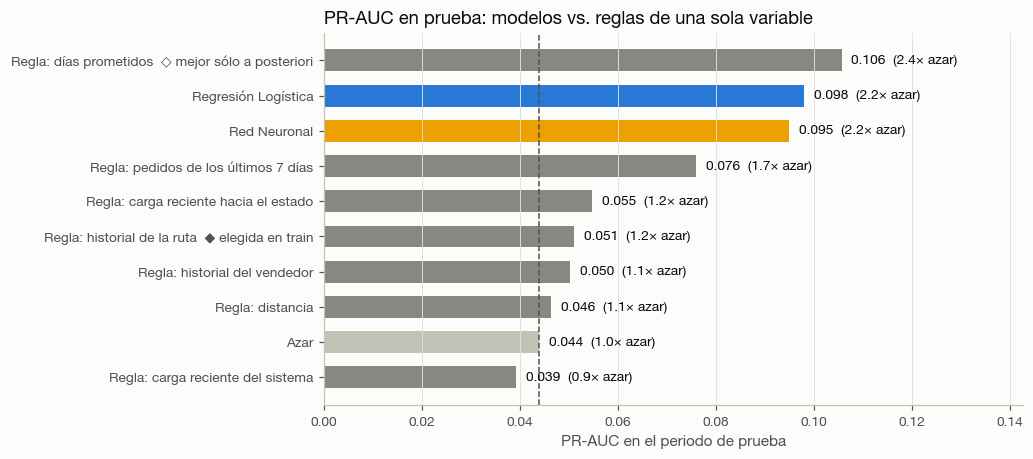

In [11]:
fig, ax = plt.subplots(figsize=(8.2, 4.4))
b = base.iloc[::-1]
colores = [viz.COLOR_MODELO.get(m, viz.NEUTRO) if t == "modelo" else ("#c3c2b7" if t == "azar" else viz.NEUTRO)
           for m, t in zip(b["Método"], b["Tipo"])]
etiquetas = [m + ("  ◆ elegida en train" if e else "  ◇ mejor sólo a posteriori" if m == posthoc["Método"] else "")
             for m, e in zip(b["Método"], b["Elegida en train"])]
ax.barh(etiquetas, b["PR-AUC"], color=colores, height=0.62)
for i, (v, x) in enumerate(zip(b["PR-AUC"], b["× azar"])):
    ax.text(v + 0.002, i, f"{v:.3f}  ({x:.1f}× azar)", va="center", fontsize=9, color=viz.TINTA)
ax.axvline(y_te.mean(), color=viz.TINTA_2, linestyle="--", linewidth=1)
ax.set_xlabel("PR-AUC en el periodo de prueba")
ax.set_xlim(0, b["PR-AUC"].max() * 1.35)
ax.set_title("PR-AUC en prueba: modelos vs. reglas de una sola variable")
ax.grid(axis="y", visible=False)
viz.guardar(fig, "baselines_test"); plt.show()

## 5. Guardar resultados para el reporte

In [12]:
def limpio(o):
    if isinstance(o, dict):
        return {k: limpio(v) for k, v in o.items()}
    if isinstance(o, list):
        return [limpio(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return float(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    return o

(config.METRICAS / "complementos.json").write_text(json.dumps(limpio(comp), ensure_ascii=False, indent=2))
print("Guardado:", config.METRICAS / "complementos.json")

Guardado: /Users/fabiolajrz/Documents/proyecto_final_equipo_3/reportes/metricas/complementos.json
